# Neuron Migration - Data Exploration

Lifeware Challenge, Neural Wave AI Hackathon. This notebook has two parts:

1. **Data Processing**: how the Neuron export is read and decoded, and which problems the raw data has.
2. **Policy walk-through**: one policy (`BL10000013`, the example of the challenge PDF) followed from issue to today,
   with the rules we can already see for the tasks t0 to t4.

# Import libraries

In [1]:
import sys
import pathlib
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '..')
from legacy_loader import LegacyData, valid_on, decode_date
from tools.policy_timeline import policy_story, plot_timeline

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

# Hyperparameters

In [2]:
project_folder = pathlib.Path('../../..').resolve()

legacy_dir = project_folder / 'legacy'

targets_dir = project_folder / 'targets'

cache_dir = project_folder / '.cache'

policy_id = 'BL10000013'

extract_date = pd.Timestamp('2026-06-30')

# Data Processing

## Raw export

The export has one `;`-separated file per table. Read as plain text, it shows the legacy formats:
blank-padded text, fixed-point numbers without a decimal point, and dates as `CYYMMDD`.

In [3]:
data = LegacyData(legacy_dir, cache_dir=cache_dir)

data.read_raw('NRPOLH').head(3)

,PH_POLNR,PH_VRSNR,PH_VRSST,PH_VLDFR,PH_VLDTO,PH_EVTNR,PH_CHGTS,PH_PRDCD,PH_STATE,PH_CCY,PH_APPDT,PH_BEGDT,PH_ENDDT,PH_FREQ,PH_PAYMT,PH_PREMI,PH_BRKNR,PH_MKTCD,PH_USRID
0,BL10000001,1,C,1070326,9999999,1,20070131154415,FLKL,10,CHF,1070128,1070326,1280326,M,LS,18500,B00260,,U538
1,BL10000003,1,S,970201,1050416,1,19970119092611,FLFX,10,CHF,970116,970201,1280201,M,LS,46000,B00176,XMAS,U771
2,BL10000003,2,C,1050417,9999999,201,20050417153048,FLFX,70,CHF,970116,970201,1280201,M,LS,46000,B00176,XMAS,U545


## Decoding rules

The data dictionary `NRDICT` gives the type and the number of decimals of **every** column, including its own.
The loader reads it first and decodes all tables with the same four rules, so there is no code per table:

| Type | Raw | Decoded | Rule |
|---|---|---|---|
| `C` text | `'BL10000001  '` | `'BL10000001'` | trim the blanks on the right |
| `N(s)` number | `18500` with `s = 2` | `185.00` | divide by `10^s` (`s = 0` stays an integer) |
| `D` date | `1250131` / `970630` | 2025-01-31 / 1997-06-30 | `CYYMMDD`, C = 0 for 19xx, 1 for 20xx: date = 19000000 + value |
| `D` date | `0` / `9999999` | NaT / `OPEN_END` (2200-12-31) | no date / open end |
| `T` timestamp | `20070131154415` | 2007-01-31 15:44:15 | `YYYYMMDDHHMMSS` |

The decoded tables are stored as parquet in `.cache/`, so `NRBOOK` (6.8 million rows) loads in under a second
after the first time. The numbers are floats for exploring; the task code converts them back to exact `Decimal`
with `to_decimal`.

In [4]:
data.dictionary[('NRPOLH', 'PH_PREMI')], data.dictionary[('NRALLO', 'AL_PCTG')], data.dictionary[('NRPOLH', 'PH_BEGDT')]

(('N', 2), ('N', 6), ('D', 0))

In [5]:
# The date rule on the two examples of SCHEMA.md, plus 'no date' and 'open end'
decode_date(pd.Series(['1250131', '970630', '0', '9999999']))

0   2025-01-31
1   1997-06-30
2          NaT
3   2200-12-31
dtype: datetime64[ns]

In [6]:
data.table('NRPOLH').head(3)

,PH_POLNR,PH_VRSNR,PH_VRSST,PH_VLDFR,PH_VLDTO,PH_EVTNR,PH_CHGTS,PH_PRDCD,PH_STATE,PH_CCY,PH_APPDT,PH_BEGDT,PH_ENDDT,PH_FREQ,PH_PAYMT,PH_PREMI,PH_BRKNR,PH_MKTCD,PH_USRID
0,BL10000001,1,C,2007-03-26,2200-12-31,1,2007-01-31 15:44:15,FLKL,10,CHF,2007-01-28,2007-03-26,2028-03-26,M,LS,185.0,B00260,,U538
1,BL10000003,1,S,1997-02-01,2005-04-16,1,1997-01-19 09:26:11,FLFX,10,CHF,1997-01-16,1997-02-01,2028-02-01,M,LS,460.0,B00176,XMAS,U771
2,BL10000003,2,C,2005-04-17,2200-12-31,201,2005-04-17 15:30:48,FLFX,70,CHF,1997-01-16,1997-02-01,2028-02-01,M,LS,460.0,B00176,XMAS,U545


## Load and decode all tables

In [7]:
overview = pd.DataFrame([
    {'table': name, 'rows': len(data.table(name)), 'columns': data.table(name).shape[1]}
    for name in data.table_names()
])
overview

,table,rows,columns
0,NRADDR,4986,10
1,NRAGRE,331,6
2,NRALLO,13720,9
3,NRBOOK,6797112,13
4,NRBROK,400,5
5,NRCHRG,33,9
6,NRCODE,66,4
7,NRCOMR,6,5
8,NRDICT,187,6
9,NRENTC,4,4


## Data quality findings

Decoding every column with the dictionary already found problems that a real migration would have:

1. **Impossible birth dates**: 10 persons are born on days that do not exist, e.g. `541131` = 31 November 1954.
   COBOL stored the date as a number and never checked it. The loader clamps them to the last day of the month and
   records them in `data.issues`. How Neuron used these dates (for the age in the risk charge) is still open.
2. **Shifted code texts**: `NRCODE` has four columns in the header but only three fields per row, so the English
   text sits in `CD_TXTDE` and `CD_TXTEN` is empty. `data.codes(domain)` takes the text that is there.
3. **Smoker flag**: `SCHEMA.md` says `Y/N`, the data has `J/N` (German *Ja*).
4. **Open end**: `9999999` cannot be stored as a pandas date, so it becomes `OPEN_END` = 2200-12-31.

In [8]:
pd.DataFrame(data.issues).merge(
    data.table('NRPERS')[['PS_BIRTH']], left_on='row', right_index=True).rename(columns={'PS_BIRTH': 'decoded'})

,table,column,row,raw,decoded
0,NRPERS,PS_BIRTH,169,541131,1954-11-30
1,NRPERS,PS_BIRTH,891,690631,1969-06-30
2,NRPERS,PS_BIRTH,950,550431,1955-04-30
3,NRPERS,PS_BIRTH,1168,891131,1989-11-30
4,NRPERS,PS_BIRTH,1188,861131,1986-11-30
5,NRPERS,PS_BIRTH,1359,710230,1971-02-28
6,NRPERS,PS_BIRTH,2540,720931,1972-09-30
7,NRPERS,PS_BIRTH,2804,760431,1976-04-30
8,NRPERS,PS_BIRTH,3031,930931,1993-09-30
9,NRPERS,PS_BIRTH,3477,640230,1964-02-29


In [9]:
code_table = data.table('NRCODE')
print(code_table.head(3))
print()
print('Smoker values:', data.table('NRPERS').PS_SMOKE.value_counts().to_dict())

  CD_DOMAIN CD_CODE                  CD_TXTDE CD_TXTEN
0     STATE      10  in force, premium paying         
1     STATE      20                   paid-up         
2     STATE      30           premium holiday         

Smoker values: {'N': 3581, 'J': 749}


## Versioned tables

`NRPOLH`, `NRALLO`, `NRHOLD`, `NRADDR` and `NRTAXR` keep a history. The row valid on a date d has
`VLDFR <= d <= VLDTO`, and if several are valid the highest `VRSNR` wins. `valid_on` implements this once for
every versioned table.

In [10]:
valid_on(data.table('NRPOLH'), 'PH', '2022-01-01', ['PH_POLNR']).query('PH_POLNR == @policy_id')

,PH_POLNR,PH_VRSNR,PH_VRSST,PH_VLDFR,PH_VLDTO,PH_EVTNR,PH_CHGTS,PH_PRDCD,PH_STATE,PH_CCY,PH_APPDT,PH_BEGDT,PH_ENDDT,PH_FREQ,PH_PAYMT,PH_PREMI,PH_BRKNR,PH_MKTCD,PH_USRID
7,BL10000013,2,S,2021-09-05,2022-04-04,128,2021-09-05 13:30:59,FLFX,30,EUR,2016-06-13,2016-08-01,2041-08-01,M,LS,315.0,B00008,,U725


## Size of the history

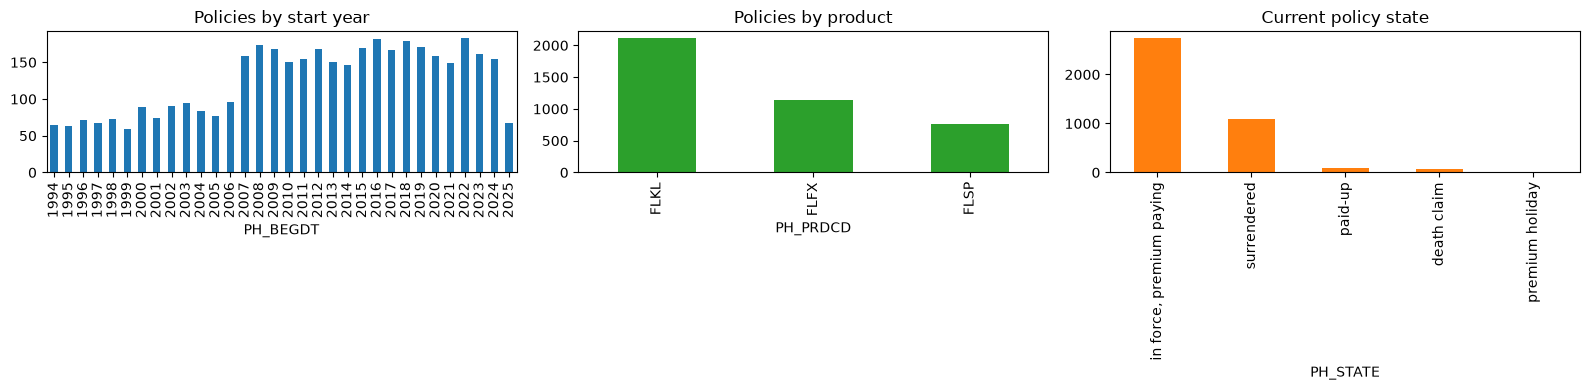

In [11]:
policies = data.table('NRPOLH').drop_duplicates('PH_POLNR', keep='last')
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))

policies.PH_BEGDT.dt.year.value_counts().sort_index().plot.bar(ax=axes[0], color='tab:blue')
axes[0].set_title('Policies by start year')

policies.PH_PRDCD.value_counts().plot.bar(ax=axes[1], color='tab:green')
axes[1].set_title('Policies by product')

policies.PH_STATE.astype(str).map(data.codes('STATE')).value_counts().plot.bar(ax=axes[2], color='tab:orange')
axes[2].set_title('Current policy state')

plt.tight_layout()
plt.show()

# Policy walk-through: BL10000013

## Contract, person, broker and product

In [12]:
story = policy_story(data, policy_id)
for name in ['NRPOLH', 'NRRISK', 'NRPERS', 'NRBROK', 'NRPROD', 'NRALLO']:
    print(f'\n{name}', 20 * '#')
    print(story[name].to_string())


NRPOLH ####################
     PH_POLNR  PH_VRSNR PH_VRSST   PH_VLDFR   PH_VLDTO  PH_EVTNR            PH_CHGTS PH_PRDCD  PH_STATE PH_CCY   PH_APPDT   PH_BEGDT   PH_ENDDT PH_FREQ PH_PAYMT  PH_PREMI PH_BRKNR PH_MKTCD PH_USRID
0  BL10000013         1        S 2016-08-01 2021-09-04         1 2016-06-16 12:14:42     FLFX        10    EUR 2016-06-13 2016-08-01 2041-08-01       M       LS     315.0   B00008              U512
1  BL10000013         2        S 2021-09-05 2022-04-04       128 2021-09-05 13:30:59     FLFX        30    EUR 2016-06-13 2016-08-01 2041-08-01       M       LS     315.0   B00008              U725
2  BL10000013         3        C 2022-04-05 2200-12-31       136 2022-04-05 11:57:52     FLFX        10    EUR 2016-06-13 2016-08-01 2041-08-01       M       LS     315.0   B00008              U615

NRRISK ####################
     RK_POLNR  RK_RSKNR RK_TARKEY  RK_PERNR  RK_SUMIN   RK_BEGDT   RK_ENDDT  RK_LOAD RK_UWCLS
0  BL10000013         1   FXU03LC  P0000012    9287.0 20

- Flex Fund Policy (`FLFX`, tariff family FX), started 2016-08-01, maturity 2041-08-01, in **EUR**.
- Monthly premium 315.00 by direct debit, sold by broker `B00008` of **tier B**.
- Tariff key `FXU03LC`: family FX, unisex (so the person's sex applies), generation 03, regular premium,
  death benefit option C (fund value plus sum insured).
- Three policy versions: a **premium holiday** (state 30) from 2021-09-05 to 2022-04-04, then back in force.
- All premiums went into fund N0002 until 2024-10-04, then 65 % N0017 and 35 % N0029.

## Timeline

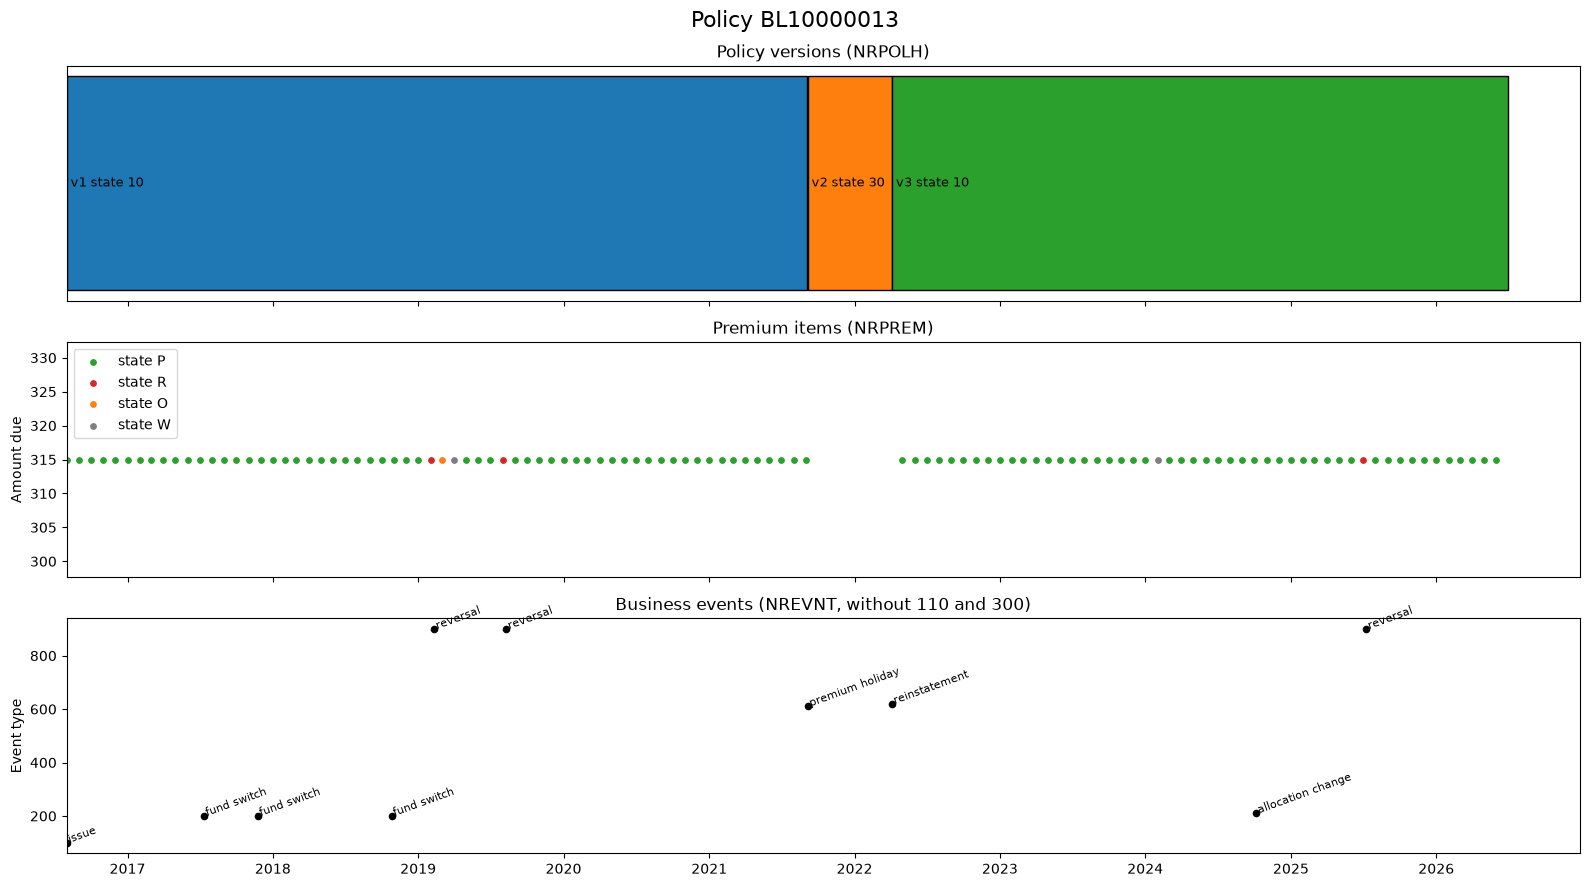

In [13]:
plot_timeline(story)

## Premium items

In [14]:
premiums = story['NRPREM']
print(premiums.PR_STATE.map(data.codes('PRSTAT')).value_counts())
premiums[premiums.PR_STATE != 'P']

PR_STATE
paid                     106
direct debit returned      3
written off                2
open                       1
Name: count, dtype: int64


,PR_POLNR,PR_DUENR,PR_DUEDT,PR_AMTDU,PR_RCVDT,PR_AMTRC,PR_STATE,PR_EVTNR
30,BL10000013,31,2019-02-01,315.0,2019-02-03,315.0,R,65
31,BL10000013,32,2019-03-01,315.0,NaT,0.0,O,0
32,BL10000013,33,2019-04-01,315.0,NaT,0.0,W,0
36,BL10000013,37,2019-08-01,315.0,2019-08-03,315.0,R,76
83,BL10000013,84,2024-02-01,315.0,NaT,0.0,W,0
100,BL10000013,101,2025-07-01,315.0,2025-07-03,315.0,R,214


112 premium items: 106 paid, 3 returned by the bank (`R`, each with a reversal event 900), 1 open and 2 written off.
There are **no items during the premium holiday**.

## Bookings

In [15]:
bookings = story['NRBOOK']
bookings.groupby(['BK_BKTYP', 'BK_POTCD']).size().unstack(fill_value=0)

BK_POTCD,1,2
BK_BKTYP,,
ADM,328,144
AMC,328,144
PRM,12,117
RSK,328,144
SWI,3,0
SWO,3,0


In [16]:
bookings[bookings.BK_BKTYP.isin(['PRM', 'ADM', 'AMC', 'RSK'])].head(8)

,BK_BOOKID,BK_POLNR,BK_EVTNR,BK_FNDID,BK_POTCD,BK_BKTYP,BK_RCVDT,BK_TRDDT,BK_PRCDT,BK_AMTPC,BK_FXRAT,BK_PRICE,BK_UNITS
0,19056,BL10000013,2,N0002,1,PRM,2016-08-03,2016-08-04,2016-08-04,NaN,NaN,NaN,NaN
1,19057,BL10000013,3,N0002,1,ADM,NaT,2016-09-01,2016-09-01,NaN,NaN,NaN,NaN
2,19058,BL10000013,3,N0002,1,AMC,NaT,2016-09-01,2016-09-01,NaN,NaN,NaN,NaN
3,19059,BL10000013,3,N0002,1,RSK,NaT,2016-09-01,2016-09-01,NaN,NaN,NaN,NaN
4,19060,BL10000013,4,N0002,1,PRM,2016-09-04,2016-09-05,2016-09-05,NaN,NaN,NaN,NaN
5,19061,BL10000013,5,N0002,1,ADM,NaT,2016-10-01,2016-09-30,NaN,NaN,NaN,NaN
6,19062,BL10000013,5,N0002,1,AMC,NaT,2016-10-01,2016-09-30,NaN,NaN,NaN,NaN
7,19063,BL10000013,5,N0002,1,RSK,NaT,2016-10-01,2016-09-30,NaN,NaN,NaN,NaN


- `PRM`, `ADM`, `AMC` and `RSK` have no amount, price or units: we must calculate them (t3).
- Charges are booked per fund and pot, so 118 charge runs give 472 rows of each type.
- The switches (`SWO`/`SWI`) are complete: amount, FX rate, price and units are given.

## Targets of this policy

What Neuron calculated for this policy, and what we can already explain with the data above.

In [17]:
targets = {name: pd.read_csv(targets_dir / f'{name}.csv') for name in
           ['t0_commission', 't1_next_due_dates', 't2_projected_maturity_value', 't3_surrender_value', 't4_annual_statement']}
for name, table in targets.items():
    print(f'\n{name}', 20 * '#')
    print(table[table.policy_id == policy_id].head(12).to_string())


t0_commission ####################
      policy_id  due_nr  amount
365  BL10000013       1    9.45
366  BL10000013       2    9.45
367  BL10000013       3    9.45
368  BL10000013       4    9.45
369  BL10000013       5    9.45
370  BL10000013       6    9.45
371  BL10000013       7    9.45
372  BL10000013       8    9.45
373  BL10000013       9    9.45
374  BL10000013      10    9.45
375  BL10000013      11    9.45
376  BL10000013      12    9.45

t1_next_due_dates ####################
     policy_id   n    due_date collection_date
24  BL10000013   1  2026-07-01      2026-07-01
25  BL10000013   2  2026-08-01      2026-08-03
26  BL10000013   3  2026-09-01      2026-09-01
27  BL10000013   4  2026-10-01      2026-10-01
28  BL10000013   5  2026-11-01      2026-11-02
29  BL10000013   6  2026-12-01      2026-12-01
30  BL10000013   7  2027-01-01      2027-01-04
31  BL10000013   8  2027-02-01      2027-02-01
32  BL10000013   9  2027-03-01      2027-03-01
33  BL10000013  10  2027-04-01      20

## First rules we can see

**t0 commission**: 9.45 = 3 % of 315.00, the `NRCOMR` rate of tier B for regular premiums.

In [18]:
commission = targets['t0_commission'].query('policy_id == @policy_id')
paid = premiums.set_index('PR_DUENR').PR_AMTRC
print('rates:', (commission.set_index('due_nr').amount / paid).round(4).value_counts().to_dict())
print('counted items:', len(commission), 'of', len(premiums), '- states:',
      premiums[premiums.PR_DUENR.isin(commission.due_nr)].PR_STATE.value_counts().to_dict())

rates: {0.03: 106}
counted items: 106 of 112 - states: {'P': 106}


**t4 entry charges**: the tier B entry charge changes from 4 % to 3 % on 2021-07-01. In 2021, 6 premiums at
4 % and 3 at 3 % give exactly 103.95, so the rate is taken on the **trade date of each premium**, not on the
application date.

In [19]:
entry_rates = data.table('NRENTC').query("EC_TIER == 'B'")
print(entry_rates)
print('2021:', 6 * 315 * 0.04 + 3 * 315 * 0.03)

  EC_TIER   EC_VLDFR   EC_VLDTO  EC_RATE
1       B 1990-01-01 2021-06-30     0.04
2       B 2021-07-01 2200-12-31     0.03
2021: 103.95


**t4 admin fees**: 6.50 per month until 2022, 8.00 from 2023 (`NRCHRG`, FX generation 03), so the admin fee is the
one valid on the charge date. The first charge is one month after the start: 2016 has 4 charges (Sep to Dec) = 26.00.

In [20]:
statement = targets['t4_annual_statement'].query('policy_id == @policy_id').set_index('year')
print((statement.admin_fees / 12).to_dict())
print(data.table('NRCHRG').query("CG_TARFAM == 'FX' and CG_TARGEN == '03'"))

{2016: 2.1666666666666665, 2017: 6.5, 2018: 6.5, 2019: 6.5, 2020: 6.5, 2021: 6.5, 2022: 6.5, 2023: 8.0, 2024: 8.0, 2025: 8.0}
   CG_TARFAM CG_TARGEN   CG_VLDFR   CG_VLDTO  CG_ADMFEE  CG_AMCP1  CG_AMCP2  CG_SMKFAC CG_MORTTB
18        FX        03 2013-01-01 2022-12-31        6.5     0.025      0.01        1.5      M12U
19        FX        03 2023-01-01 2200-12-31        8.0     0.025      0.01        1.5      M12U


**Pots**: the Flex product has `PD_INIMON = 12`, and exactly the first 12 premiums buy units of the initial pot 1.
Everything after goes to the base pot 2.

In [21]:
bookings.query("BK_BKTYP == 'PRM'").groupby('BK_POTCD').BK_TRDDT.agg(['min', 'max', 'count'])

,min,max,count
BK_POTCD,,,
1,2016-08-04,2017-07-07,12
2,2017-08-07,2026-06-03,117


**Trade and price dates**: a premium is invested on the business day after the money date; a charge on a weekend
anniversary is priced on the business day before.

**t1 collection dates**: due dates stay on the 1st, collection moves to the next business day
(2026-08-01 is a Saturday -> 2026-08-03, 2027-01-01 is a holiday -> 2027-01-04).

In [22]:
dates = bookings[['BK_BKTYP', 'BK_RCVDT', 'BK_TRDDT', 'BK_PRCDT']].head(8).copy()
for column in ['BK_RCVDT', 'BK_TRDDT', 'BK_PRCDT']:
    dates[column + '_day'] = dates[column].dt.day_name()
dates

,BK_BKTYP,BK_RCVDT,BK_TRDDT,BK_PRCDT,BK_RCVDT_day,BK_TRDDT_day,BK_PRCDT_day
0,PRM,2016-08-03,2016-08-04,2016-08-04,Wednesday,Thursday,Thursday
1,ADM,NaT,2016-09-01,2016-09-01,NaN,Thursday,Thursday
2,AMC,NaT,2016-09-01,2016-09-01,NaN,Thursday,Thursday
3,RSK,NaT,2016-09-01,2016-09-01,NaN,Thursday,Thursday
4,PRM,2016-09-04,2016-09-05,2016-09-05,Sunday,Monday,Monday
5,ADM,NaT,2016-10-01,2016-09-30,NaN,Saturday,Friday
6,AMC,NaT,2016-10-01,2016-09-30,NaN,Saturday,Friday
7,RSK,NaT,2016-10-01,2016-09-30,NaN,Saturday,Friday


In [23]:
next_dates = targets['t1_next_due_dates'].query('policy_id == @policy_id').copy()
next_dates['due_day'] = pd.to_datetime(next_dates.due_date).dt.day_name()
next_dates['collection_day'] = pd.to_datetime(next_dates.collection_date).dt.day_name()
next_dates

,policy_id,n,due_date,collection_date,due_day,collection_day
24,BL10000013,1,2026-07-01,2026-07-01,Wednesday,Wednesday
25,BL10000013,2,2026-08-01,2026-08-03,Saturday,Monday
26,BL10000013,3,2026-09-01,2026-09-01,Tuesday,Tuesday
27,BL10000013,4,2026-10-01,2026-10-01,Thursday,Thursday
28,BL10000013,5,2026-11-01,2026-11-02,Sunday,Monday
29,BL10000013,6,2026-12-01,2026-12-01,Tuesday,Tuesday
30,BL10000013,7,2027-01-01,2027-01-04,Friday,Monday
31,BL10000013,8,2027-02-01,2027-02-01,Monday,Monday
32,BL10000013,9,2027-03-01,2027-03-01,Monday,Monday
33,BL10000013,10,2027-04-01,2027-04-01,Thursday,Thursday


# Summary

| Area | Finding |
|---|---|
| Loader | One generic decoder driven by `NRDICT` reads all 27 tables |
| Data quality | Impossible birth dates, shifted `NRCODE` texts, smoker flag `J/N` |
| t0 | Commission = received premium x tier rate; returned and unpaid items are not counted |
| t1 | Due dates on the start day; collection on the next business day (holiday calendar needed) |
| t3 | Premiums of the first `PD_INIMON` months go to pot 1; charges are booked per fund and pot |
| t4 | Entry charge rate on the premium's trade date; admin fee valid on the charge date |

Next step: turn these into code for t0 and score it with `check.py`.